# Naive Bayes with a False-Positive-Constrained Threshold

For this ad-blocking task, a false positive means real non-ad content is incorrectly blocked. We require a validation false-positive rate of no more than 5%, then maximize ad recall under that constraint.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline

In [2]:
candidates = [
    Path.cwd() / "ml" / "dataset" / "ad.data",
    Path.cwd() / "dataset" / "ad.data",
]
dataset_path = next((path for path in candidates if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError("Could not find ml/dataset/ad.data")

df = pd.read_csv(dataset_path, header=None, skipinitialspace=True, na_values="?")
df = df.drop_duplicates().reset_index(drop=True)

X = df.iloc[:, :-1]
y = df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")

print(f"Dataset shape after duplicate removal: {df.shape}")
print("Class distribution:")
print(y.value_counts())

Dataset shape after duplicate removal: (2423, 1559)
Class distribution:
1558
nonad    2037
ad        386
Name: count, dtype: Int64


In [3]:
# Reserve 20% for final test evaluation.
X_fit, X_test, y_fit, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Use 25% of the remaining data as a threshold-validation set.
X_train, X_validation, y_train, y_validation = train_test_split(
    X_fit, y_fit, test_size=0.25, random_state=42, stratify=y_fit
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_validation))
print("Test rows:", len(X_test))

Training rows: 1453
Validation rows: 485
Test rows: 485


In [4]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", BernoulliNB()),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputat

In [5]:
MAX_FALSE_POSITIVE_RATE = 0.05
ad_index = list(model.classes_).index("ad")
validation_ad_probability = model.predict_proba(X_validation)[:, ad_index]
validation_binary = y_validation.eq("ad").astype(int)

threshold_results = []
candidate_thresholds = np.unique(np.concatenate((
    np.array([0.0]),
    validation_ad_probability,
)))

non_ad_count = int((validation_binary == 0).sum())
ad_count = int((validation_binary == 1).sum())

for threshold in candidate_thresholds:
    predicted_ad = (validation_ad_probability >= threshold).astype(int)
    false_positives = int(((predicted_ad == 1) & (validation_binary == 0)).sum())
    false_positive_rate = false_positives / non_ad_count
    precision = precision_score(validation_binary, predicted_ad, pos_label=1, zero_division=0)
    recall = recall_score(validation_binary, predicted_ad, pos_label=1, zero_division=0)
    threshold_results.append((threshold, false_positive_rate, precision, recall, false_positives))

eligible = [row for row in threshold_results if row[1] <= MAX_FALSE_POSITIVE_RATE]
if not eligible:
    raise RuntimeError("No threshold satisfies the false-positive limit")

# Select the threshold with highest validation recall; precision breaks ties.
threshold, val_fpr, val_precision, val_recall, _ = max(
    eligible,
    key=lambda row: (row[3], row[2], -row[1]),
)

print(f"Selected threshold: {threshold:.3f}")
print(f"Validation false-positive rate limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
print(f"Validation false-positive rate: {val_fpr:.3%}")
print(f"Validation ad precision: {val_precision:.4f}")
print(f"Validation ad recall: {val_recall:.4f}")

Selected threshold: 0.001
Validation false-positive rate limit: <= 5.0%
Validation false-positive rate: 3.676%
Validation ad precision: 0.8052
Validation ad recall: 0.8052


False-positive limit: <= 5.0%
Test false positives: 10 / 408
Test false-positive rate: 2.451%
Test ad precision: 0.8571
Test ad recall: 0.7792
Test F1 for ad: 0.8163
Test accuracy: 0.9443

Classification report (ad = positive class):
              precision    recall  f1-score   support

       nonad       0.96      0.98      0.97       408
          ad       0.86      0.78      0.82        77

    accuracy                           0.94       485
   macro avg       0.91      0.88      0.89       485
weighted avg       0.94      0.94      0.94       485



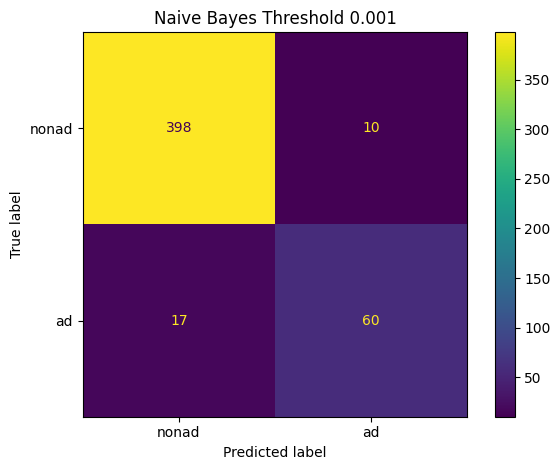

In [6]:
test_ad_probability = model.predict_proba(X_test)[:, ad_index]
y_test_binary = y_test.eq("ad").astype(int)
y_pred_binary = (test_ad_probability >= threshold).astype(int)

test_false_positive_count = ((y_pred_binary == 1) & (y_test_binary == 0)).sum()
test_non_ad_count = (y_test_binary == 0).sum()
test_false_positive_rate = test_false_positive_count / test_non_ad_count
test_precision = precision_score(y_test_binary, y_pred_binary, pos_label=1)
test_recall = recall_score(y_test_binary, y_pred_binary, pos_label=1)

print(f"False-positive limit: <= {MAX_FALSE_POSITIVE_RATE:.1%}")
print(f"Test false positives: {test_false_positive_count} / {test_non_ad_count}")
print(f"Test false-positive rate: {test_false_positive_rate:.3%}")
print(f"Test ad precision: {test_precision:.4f}")
print(f"Test ad recall: {test_recall:.4f}")
print(f"Test F1 for ad: {f1_score(y_test_binary, y_pred_binary, pos_label=1):.4f}")
print(f"Test accuracy: {accuracy_score(y_test_binary, y_pred_binary):.4f}")

print("\nClassification report (ad = positive class):")
print(classification_report(y_test_binary, y_pred_binary, target_names=["nonad", "ad"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test_binary,
    y_pred_binary,
    display_labels=["nonad", "ad"],
)
plt.title(f"Naive Bayes Threshold {threshold:.3f}")
plt.tight_layout()
plt.show()